## 5. Comparación con el mismo presupuesto
Presupuesto = **30 %** de lo que costaría llamar a todos los créditos de la validación. Seis estrategias:

| Estrategia | ¿Qué aísla? |
|---|---|
| Sin modelo: todos por llamada (sin límite) | Referencia de gestión masiva |
| Sin modelo: al azar, llamada | Gestión actual con presupuesto limitado |
| **Sin modelo: WhatsApp a todos + llamadas al azar** | ¿La ganancia es solo por usar **canales baratos**? |
| Con modelo: prioriza por P×saldo, llamada | Valor **solo de la priorización** |
| **Con modelo: WhatsApp a todos + llamadas priorizadas** | **Misma mezcla y costo que la anterior sin modelo: la única diferencia es a quién se llama** |
| Con modelo: prioriza + canal por segmento | Canal optimizado por segmento con el entrenamiento |

📋 **Pega esta tabla** (es la tabla central del ROI).

# 08 — Simulación de campaña y ROI

**Pregunta de negocio:** con el **mismo presupuesto** de cobranza, ¿cuánto más se recupera usando el modelo que gestionando sin él?

**Cómo se simula** (Prosper no registra gestiones; todo lo de canales es **supuesto explícito**, `src/supuestos.py` y `src/simulacion.py`):
- La recuperación **real** de Prosper = lo que logra la gestión más intensiva (negociación, efectividad 1,0).
- Contactado por el canal *c* → recupera real × efectividad(*c*). No contactado → real × 10 % (pago espontáneo). Venta → 4 % del saldo.
- **KPI:** USD recuperados **por encima de no hacer nada**, por cada USD invertido.

**Regla anti-trampa:** el canal de cada segmento se elige con el **entrenamiento**; las estrategias se comparan en la **validación** (desenlace real, nunca visto por el modelo).

**Resultados que guarda:** tablas `campanas` y `campana_asignaciones` en PostgreSQL, `docs/roi_*.csv`, `docs/figuras/08_*.png`.

## 1. Preparación

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

from src.config import RUTAS
from src.bd import obtener_motor
from src.variables import leer_base, saldo_al_default
from src.simulacion import (SUPUESTOS_SIMULACION, catalogo_canales, elegir_canal_por_segmento,
                            optimizar_canales, orden_modelo, simular, estrategias)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
FRACCION_PRESUPUESTO = 0.30   # presupuesto = 30 % de lo que costaría llamar a todos

def guardar_figura(fig, nombre):
    fig.savefig(RUTAS['figuras'] / nombre, dpi=150, bbox_inches='tight')

## 2. Datos: desenlace real + predicciones vigentes (desde PostgreSQL)

In [2]:
motor = obtener_motor()
base = leer_base(motor)
with motor.connect() as con:
    pred = pd.read_sql(text('SELECT credito_id, prob_recuperar, segmento_id FROM predicciones WHERE es_vigente'), con)
    segmentos = pd.read_sql(text('SELECT segmento_id, nombre FROM segmentos ORDER BY segmento_id'), con)
for c in ['prob_recuperar']:
    pred[c] = pred[c].astype(float)

metricas = json.loads((RUTAS['models'] / 'metricas.json').read_text(encoding='utf-8'))
TASA = metricas['segmentacion']['tasa_media_entrenamiento']

base['saldo_estimado'] = saldo_al_default(base).fillna(base['monto_original'] * metricas['ratio_saldo_mediano'])
df = base.merge(pred, on='credito_id', how='inner')
df['monto_esperado_modelo'] = df['prob_recuperar'] * TASA * df['saldo_estimado']

ent = df[df['conjunto'] == 'entrenamiento'].reset_index(drop=True)
val = df[df['conjunto'] == 'validacion'].reset_index(drop=True)
print(f'Entrenamiento: {len(ent):,} | Validación: {len(val):,} | USD reales en validación: {val["recuperacion_total"].sum():,.0f}')

Entrenamiento: 8,543 | Validación: 3,163 | USD reales en validación: 1,182,216


## 3. Supuestos

In [3]:
cat = catalogo_canales()
sup = dict(SUPUESTOS_SIMULACION)
print('Supuestos de simulación:', sup)
cat

Supuestos de simulación: {'recuperacion_sin_gestion': 0.1, 'precio_venta_pct_saldo': 0.04}


,canal_id,costo,efectividad
nombre,,,
SMS,1,0.05,0.40
WhatsApp,2,0.10,0.55
Llamada de asesor,3,3.00,0.80
Negociación con asesor,4,15.00,1.00
Venta de cartera,5,0.00,NaN


## 4. Canal por segmento (optimizado con el ENTRENAMIENTO)
Las columnas `valor_*` muestran cuánto rinde **cada crédito** con cada canal (recuperación ganada − costo). Pero con presupuesto limitado lo que importa es el rendimiento **por dólar**: un canal caro alcanza para pocos deudores. Por eso `canal_optimizado` se elige simulando la campaña **en el entrenamiento** con el presupuesto de la sección 5 y probando un segmento a la vez.

📋 **Pega esta tabla.**

In [4]:
eleccion = elegir_canal_por_segmento(ent, cat, sup).rename(columns={'canal_elegido': 'mejor_por_credito'})
eleccion['canal_optimizado'] = optimizar_canales(ent, cat, sup, FRACCION_PRESUPUESTO)
eleccion = segmentos.set_index('segmento_id').join(eleccion)
canal_modelo = val['segmento_id'].map(eleccion['canal_optimizado'])
eleccion[['nombre', 'canal_optimizado', 'mejor_por_credito'] + [c for c in eleccion if c.startswith('valor_')]]

,nombre,canal_optimizado,mejor_por_credito,valor_SMS,valor_WhatsApp,valor_Llamada de asesor,valor_Negociación con asesor,valor_Venta de cartera,valor_No gestionar
segmento_id,,,,,,,,,
1,Default en primera cuota (revisión de fraude),Negociación con asesor,Negociación con asesor,803.35,1205.00,1871.60,2395.19,29.40,0.0
2,Contacto selectivo,Venta de cartera,Venta de cartera,63.30,94.92,144.81,175.04,274.64,0.0
3,Negociación prioritaria,WhatsApp,Negociación con asesor,100.30,150.43,231.15,286.05,137.46,0.0
4,Recordatorio automático,Llamada de asesor,Negociación con asesor,103.50,155.22,238.62,295.65,26.52,0.0
5,Baja recuperación / venta de cartera,Venta de cartera,Venta de cartera,13.53,20.27,28.68,25.74,33.95,0.0


Costo de llamar a todos: USD 9,489 | Presupuesto de la campaña: USD 2,847


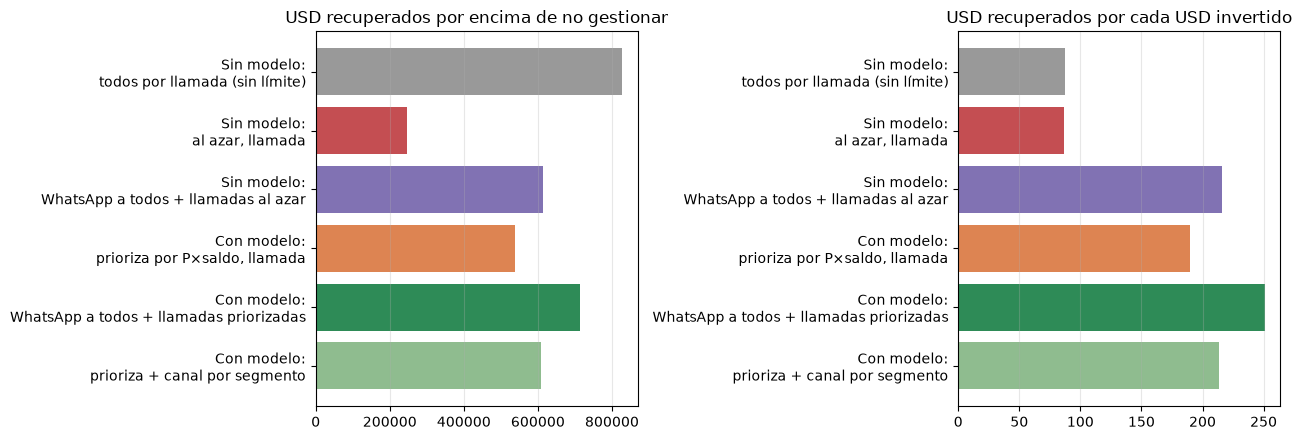

,creditos_gestionados,costo_usd,recuperado_usd,incremental_usd,neto_usd,usd_por_usd_invertido
Sin modelo: todos por llamada (sin límite),3163.0,9489.0,945772.86,827551.25,818062.25,87.21
"Sin modelo: al azar, llamada",948.0,2844.0,364791.97,246570.36,243726.36,86.70
Sin modelo: WhatsApp a todos + llamadas al azar,3163.0,2845.1,731532.13,613310.52,610465.42,215.57
"Con modelo: prioriza por P×saldo, llamada",948.0,2844.0,656904.07,538682.46,535838.46,189.41
Con modelo: WhatsApp a todos + llamadas priorizadas,3163.0,2845.1,832054.72,713833.11,710988.01,250.90
Con modelo: prioriza + canal por segmento,3009.0,2844.7,726737.85,608516.24,605671.54,213.91


In [5]:
costo_todos = len(val) * cat.loc['Llamada de asesor', 'costo']
PRESUPUESTO = FRACCION_PRESUPUESTO * costo_todos
print(f'Costo de llamar a todos: USD {costo_todos:,.0f} | Presupuesto de la campaña: USD {PRESUPUESTO:,.0f}')

tabla_roi = estrategias(val, canal_modelo, PRESUPUESTO, cat, sup)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
nombres = [n.replace(': ', ':\n') for n in tabla_roi.index]
axes[0].barh(nombres, tabla_roi['incremental_usd'], color=['#999999', '#C44E52', '#8172B3', '#DD8452', '#2E8B57', '#8FBC8F'])
axes[0].set_title('USD recuperados por encima de no gestionar'); axes[0].invert_yaxis()
axes[1].barh(nombres, tabla_roi['usd_por_usd_invertido'], color=['#999999', '#C44E52', '#8172B3', '#DD8452', '#2E8B57', '#8FBC8F'])
axes[1].set_title('USD recuperados por cada USD invertido'); axes[1].invert_yaxis()
for ax in axes: ax.grid(axis='x', alpha=.3)
plt.tight_layout(); guardar_figura(fig, '08_roi_estrategias.png'); plt.show()
tabla_roi

## 6. ¿Y con otros presupuestos?
Curva de USD incrementales según el presupuesto (% del costo de llamar a todos). Para cada presupuesto se **re-optimizan** los canales con el entrenamiento.

📋 **Pega esta tabla.**

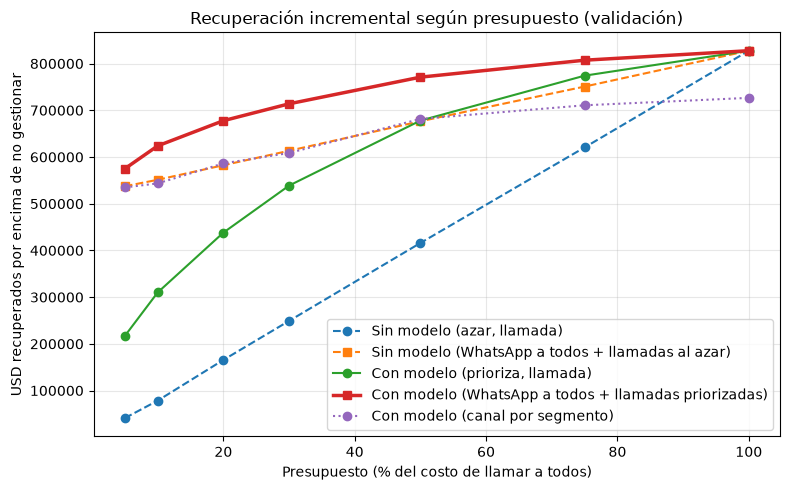

,presupuesto_pct,presupuesto_usd,azar_incremental,hibrido_sin_modelo_incremental,modelo_llamada_incremental,mezcla_con_modelo_incremental,modelo_completo_incremental,modelo_completo_costo,ganancia_mezcla_vs_mejor_sin_modelo_pct
0,5,474,40949.03,537323.82,216830.13,574835.93,534864.67,472.1,7.0
1,10,949,78347.24,551199.63,309915.59,623796.68,543473.98,948.7,13.2
2,20,1898,165484.52,582356.24,438003.50,677679.81,586348.03,1895.1,16.4
3,30,2847,249001.23,613307.01,538682.46,713833.11,608516.24,2844.7,16.4
4,50,4744,415876.26,676510.34,677933.73,770923.52,681567.41,4591.4,14.0
5,75,7117,620506.19,750763.45,774097.71,807224.18,710691.76,5763.0,7.5
6,100,9489,827551.25,827551.25,827551.25,827551.25,726606.23,9486.0,0.0


In [6]:
fracciones = [0.05, 0.10, 0.20, 0.30, 0.50, 0.75, 1.00]
filas = []
for f in fracciones:
    canal_f = val['segmento_id'].map(optimizar_canales(ent, cat, sup, f))  # re-optimiza para cada presupuesto
    t = estrategias(val, canal_f, f * costo_todos, cat, sup, semillas=10)
    filas.append({'presupuesto_pct': int(f * 100), 'presupuesto_usd': round(f * costo_todos),
                  'azar_incremental': t.loc['Sin modelo: al azar, llamada', 'incremental_usd'],
                  'hibrido_sin_modelo_incremental': t.loc['Sin modelo: WhatsApp a todos + llamadas al azar', 'incremental_usd'],
                  'modelo_llamada_incremental': t.loc['Con modelo: prioriza por P×saldo, llamada', 'incremental_usd'],
                  'mezcla_con_modelo_incremental': t.loc['Con modelo: WhatsApp a todos + llamadas priorizadas', 'incremental_usd'],
                  'modelo_completo_incremental': t.loc['Con modelo: prioriza + canal por segmento', 'incremental_usd'],
                  'modelo_completo_costo': t.loc['Con modelo: prioriza + canal por segmento', 'costo_usd']})
curva = pd.DataFrame(filas)
mejor_sin = curva[['azar_incremental', 'hibrido_sin_modelo_incremental']].max(axis=1)
curva['ganancia_mezcla_vs_mejor_sin_modelo_pct'] = ((curva['mezcla_con_modelo_incremental'] / mejor_sin - 1) * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curva['presupuesto_pct'], curva['azar_incremental'], 'o--', label='Sin modelo (azar, llamada)')
ax.plot(curva['presupuesto_pct'], curva['hibrido_sin_modelo_incremental'], 's--', label='Sin modelo (WhatsApp a todos + llamadas al azar)')
ax.plot(curva['presupuesto_pct'], curva['modelo_llamada_incremental'], 'o-', label='Con modelo (prioriza, llamada)')
ax.plot(curva['presupuesto_pct'], curva['mezcla_con_modelo_incremental'], 's-', lw=2.5, label='Con modelo (WhatsApp a todos + llamadas priorizadas)')
ax.plot(curva['presupuesto_pct'], curva['modelo_completo_incremental'], 'o:', label='Con modelo (canal por segmento)')
ax.set_xlabel('Presupuesto (% del costo de llamar a todos)'); ax.set_ylabel('USD recuperados por encima de no gestionar')
ax.set_title('Recuperación incremental según presupuesto (validación)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); guardar_figura(fig, '08_curva_presupuesto.png'); plt.show()
curva

## 7. Análisis de sensibilidad: ¿y si los supuestos están mal?
Se cambia **un supuesto a la vez** (y un escenario pesimista combinado). En cada escenario el canal por segmento se **vuelve a elegir con el entrenamiento** y se comparan la **mejor** estrategia sin modelo y la **mejor** con modelo, con el mismo presupuesto (30 %).

📋 **Pega esta tabla.**

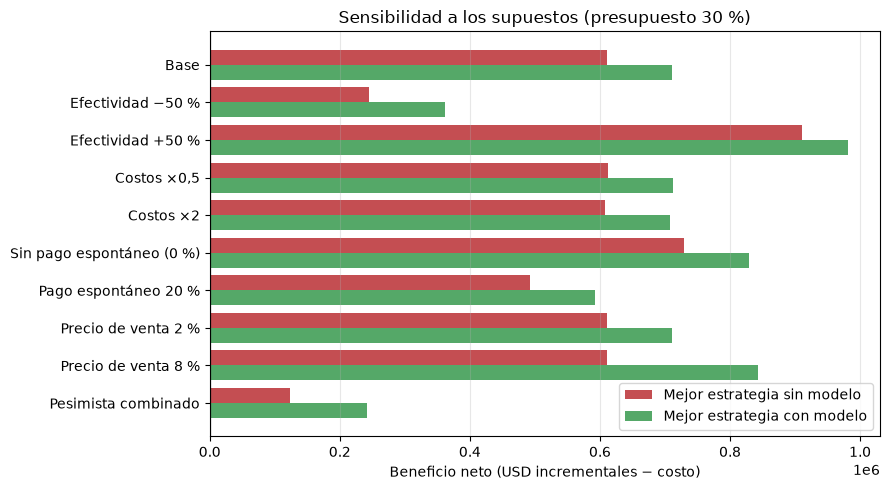

El modelo gana en 10 de 10 escenarios


,mejor_sin_modelo,sin_modelo_usd_por_usd,modelo_usd_por_usd,sin_modelo_neto_usd,modelo_neto_usd,ganancia_pct,modelo_gana
escenario,,,,,,,
Base,WhatsApp a todos + llamadas al azar,215.56,250.90,610461.91,710988.01,16.5,True
Efectividad −50 %,WhatsApp a todos + llamadas al azar,87.01,128.23,244697.61,361828.11,47.9,True
Efectividad +50 %,WhatsApp a todos + llamadas al azar,321.26,346.00,911178.40,981546.67,7.7,True
"Costos ×0,5",WhatsApp a todos + llamadas al azar,431.13,501.80,611884.46,712410.56,16.4,True
Costos ×2,WhatsApp a todos + llamadas al azar,107.78,125.45,607616.81,708142.91,16.5,True
Sin pago espontáneo (0 %),WhatsApp a todos + llamadas al azar,257.12,292.45,728683.52,829209.62,13.8,True
Pago espontáneo 20 %,WhatsApp a todos + llamadas al azar,174.01,209.35,492240.31,592766.41,20.4,True
Precio de venta 2 %,WhatsApp a todos + llamadas al azar,215.56,250.90,610461.91,710988.01,16.5,True
Precio de venta 8 %,WhatsApp a todos + llamadas al azar,215.56,297.42,610461.91,843028.55,38.1,True


In [7]:
escenarios = {
    'Base': dict(),
    'Efectividad −50 %': dict(mult_efectividad=0.5),
    'Efectividad +50 %': dict(mult_efectividad=1.5),
    'Costos ×0,5': dict(mult_costo=0.5),
    'Costos ×2': dict(mult_costo=2.0),
    'Sin pago espontáneo (0 %)': dict(recuperacion_sin_gestion=0.0),
    'Pago espontáneo 20 %': dict(recuperacion_sin_gestion=0.20),
    'Precio de venta 2 %': dict(precio_venta_pct_saldo=0.02),
    'Precio de venta 8 %': dict(precio_venta_pct_saldo=0.08),
    'Pesimista combinado': dict(mult_efectividad=0.5, mult_costo=2.0, recuperacion_sin_gestion=0.20),
}
filas = []
for nombre, cambios in escenarios.items():
    cat_e = catalogo_canales(cambios.get('mult_costo', 1.0), cambios.get('mult_efectividad', 1.0))
    sup_e = {**SUPUESTOS_SIMULACION, **{k: v for k, v in cambios.items() if k in SUPUESTOS_SIMULACION}}
    asign_e = optimizar_canales(ent, cat_e, sup_e, FRACCION_PRESUPUESTO)
    canal_e = val['segmento_id'].map(asign_e)
    presupuesto_e = FRACCION_PRESUPUESTO * len(val) * cat_e.loc['Llamada de asesor', 'costo']
    t = estrategias(val, canal_e, presupuesto_e, cat_e, sup_e, semillas=10)
    sin_modelo = t.loc[['Sin modelo: al azar, llamada', 'Sin modelo: WhatsApp a todos + llamadas al azar']]
    a = sin_modelo.loc[sin_modelo['neto_usd'].idxmax()]          # la MEJOR estrategia sin modelo
    con_modelo = t.loc[['Con modelo: WhatsApp a todos + llamadas priorizadas', 'Con modelo: prioriza + canal por segmento']]
    m = con_modelo.loc[con_modelo['neto_usd'].idxmax()]          # la MEJOR estrategia con modelo
    filas.append({'escenario': nombre,
                  'mejor_sin_modelo': a.name.replace('Sin modelo: ', ''),
                  'sin_modelo_usd_por_usd': a['usd_por_usd_invertido'], 'modelo_usd_por_usd': m['usd_por_usd_invertido'],
                  'sin_modelo_neto_usd': a['neto_usd'], 'modelo_neto_usd': m['neto_usd'],
                  'ganancia_pct': round((m['neto_usd'] / a['neto_usd'] - 1) * 100, 1),
                  'modelo_gana': m['neto_usd'] > a['neto_usd'],
                  'canales': ' | '.join(f'{i}:{c}' for i, c in asign_e.items())})
sensibilidad = pd.DataFrame(filas).set_index('escenario')

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(sensibilidad))
ax.barh(y - 0.2, sensibilidad['sin_modelo_neto_usd'], 0.4, label='Mejor estrategia sin modelo', color='#C44E52')
ax.barh(y + 0.2, sensibilidad['modelo_neto_usd'], 0.4, label='Mejor estrategia con modelo', color='#55A868')
ax.set_yticks(y, sensibilidad.index); ax.invert_yaxis(); ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('Beneficio neto (USD incrementales − costo)'); ax.set_title('Sensibilidad a los supuestos (presupuesto 30 %)')
ax.legend(); ax.grid(axis='x', alpha=.3)
plt.tight_layout(); guardar_figura(fig, '08_sensibilidad.png'); plt.show()
print(f"El modelo gana en {sensibilidad['modelo_gana'].sum()} de {len(sensibilidad)} escenarios")
sensibilidad.drop(columns='canales')

## 8. Guardar las dos campañas en PostgreSQL (para Power BI)

In [8]:
canal_id = cat['canal_id'].to_dict()
sup_json = {'simulacion': sup, 'canales': json.loads(cat.reset_index().to_json(orient='records')),  # NaN -> null (JSON válido)
            'presupuesto_usd': float(round(PRESUPUESTO, 2)), 'fraccion_presupuesto': FRACCION_PRESUPUESTO,
            'evaluacion': 'validacion (cierres 2010+)'}
llamada = pd.Series('Llamada de asesor', index=val.index)
campanas = {
    ('Sin modelo: al azar, llamada', 'sin_modelo'): simular(val, np.random.default_rng(0).permutation(len(val)), llamada, PRESUPUESTO, cat, sup),
    ('Con modelo: prioriza + canal por segmento', 'con_modelo'): None,
}
campanas[('Con modelo: prioriza + canal por segmento', 'con_modelo')] = simular(val, orden_modelo(val, canal_modelo, cat, sup), canal_modelo, PRESUPUESTO, cat, sup)

with motor.begin() as con:
    con.exec_driver_sql('TRUNCATE campana_asignaciones, campanas RESTART IDENTITY')
    for (nombre, escenario), res in campanas.items():
        cid = con.execute(text("""INSERT INTO campanas (nombre, escenario, modelo_version, presupuesto_usd, supuestos)
                                 VALUES (:n, :e, :v, :p, CAST(:s AS JSONB)) RETURNING campana_id"""),
                          {'n': nombre, 'e': escenario, 'v': metricas['segmentacion']['modelo_version'] if escenario == 'con_modelo' else None,
                           'p': float(round(PRESUPUESTO, 2)), 's': json.dumps(sup_json, ensure_ascii=False, default=str)}).scalar()
        d = res['detalle']
        pd.DataFrame({'campana_id': cid, 'credito_id': d['credito_id'].astype(int),
                      'canal_id': d['canal'].map(canal_id).astype('Int64'), 'contactado': d['contactado'],
                      'costo_usd': d['costo_usd'].round(2), 'recuperacion_simulada': d['recuperacion_simulada'].round(2)}
                     ).to_sql('campana_asignaciones', con, if_exists='append', index=False, method='multi', chunksize=1000)
        print(f'✅ Campaña {cid}: {nombre} ({len(d):,} asignaciones)')

✅ Campaña 1: Sin modelo: al azar, llamada (3,163 asignaciones)


✅ Campaña 2: Con modelo: prioriza + canal por segmento (3,163 asignaciones)


## 9. Guardar archivos

In [9]:
tabla_roi.to_csv(RUTAS['docs'] / 'roi_estrategias.csv', encoding='utf-8-sig')
curva.to_csv(RUTAS['docs'] / 'roi_curva_presupuesto.csv', index=False, encoding='utf-8-sig')
sensibilidad.to_csv(RUTAS['docs'] / 'roi_sensibilidad.csv', encoding='utf-8-sig')
eleccion.to_csv(RUTAS['docs'] / 'roi_canal_por_segmento.csv', encoding='utf-8-sig')
metricas['roi'] = {'presupuesto_usd': round(PRESUPUESTO, 2), 'supuestos': sup,
                   'estrategias': tabla_roi.to_dict(orient='index')}
(RUTAS['models'] / 'metricas.json').write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=float), encoding='utf-8')
print('✅ docs/roi_*.csv, docs/figuras/08_*.png, models/metricas.json')

✅ docs/roi_*.csv, docs/figuras/08_*.png, models/metricas.json
